# Week 8 Lab - Recover an AES key byte with CPA

Capture power traces while the target encrypts random plaintexts under a fixed AES-128 key, then recover
the first key byte with **correlation power analysis (CPA)**: predict the Hamming weight of
`Sbox(plaintext XOR guess)` for every trace, correlate that prediction against the measured power, and keep
the guess that correlates best. Based on ChipWhisperer `sca101` Lab 4_2.

**What you do, in order:**

1. Build and flash the AES firmware, and check that the target's ciphertext matches a reference AES.
2. Look at one power trace and set the gain so it does not clip.
3. Capture 500 traces: same secret key, a different random plaintext each time.
4. Look at the traces by eye. They all look the same, so the key cannot be read off them (SPA fails).
5. Run CPA on key byte 0: 256 guesses, one correlation each. One guess stands out.
6. Check the leak directly. Grouped by the right guess, the mean traces fan out by Hamming weight;
   grouped by a wrong guess they do not.
7. Find how many traces the attack actually needed, then recover all 16 bytes.
8. Submit the correlation plot, the recovered byte and the trace count.

**Hardware:** Husky + CW313 + CW312T-SAM4S. Connect the Husky's **MEASURE** SMA to the CW313 with the
coax (the power trace comes over that cable). No crowbar is needed: nothing is glitched this week, the target
runs correctly the whole time. The notebook finds your ChipWhisperer install automatically, so it runs from
anywhere.

In [1]:
SCOPETYPE     = 'OPENADC'
PLATFORM      = 'CW312_SAM4S'
CRYPTO_TARGET = 'TINYAES128C'   # software AES; tiny-AES runs SubBytes as a table lookup in firmware
SS_VER        = 'SS_VER_2_1'

In [2]:
# Locate the ChipWhisperer install from the installed package, so this notebook
# runs from anywhere - it does not need to sit inside the chipwhisperer tree.
import os, chipwhisperer as cw
CWROOT = os.path.normpath(os.path.join(os.path.dirname(cw.__file__), "..", ".."))
SETUP  = os.path.join(CWROOT, "jupyter", "Setup_Scripts", "Setup_Generic.ipynb")
FW_SRC = os.path.join(CWROOT, "firmware", "mcu", "simpleserial-aes")
# drive-less, forward-slash root for the %%bash build cell; the cell itself finds
# the right mount prefix (/mnt/c on WSL, /c on Git-Bash, / on macOS/Linux).
CW_BASH = (CWROOT[0].lower() + CWROOT[2:].replace("\\", "/")) if os.name == "nt" else CWROOT.lstrip("/")
print("ChipWhisperer:", CWROOT)

ChipWhisperer: C:\Users\MykhailoOkhrimenko\ChipWhisperer\chipwhisperer


In [3]:
%run "$SETUP"    # brings up scope, prog, target

INFO: Found ChipWhisperer😍


scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 131124                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen                   
scope.glitch.phase_

In [4]:
%%bash -s "$PLATFORM" "$CRYPTO_TARGET" "$SS_VER" "$CW_BASH"
# find the firmware dir under whichever mount this bash uses (WSL /mnt/c, Git-Bash /c, macOS /)
FW=""
for p in "/mnt/$4" "/$4"; do
  [ -d "$p/firmware/mcu/simpleserial-aes" ] && FW="$p/firmware/mcu/simpleserial-aes" && break
done
[ -z "$FW" ] && { echo "firmware dir not found for root: $4" >&2; exit 1; }
cd "$FW"
make PLATFORM=$1 CRYPTO_TARGET=$2 SS_VER=$3 -j

Building for platform CW312_SAM4S with CRYPTO_TARGET=TINYAES128C


SS_VER set to SS_VER_2_1


SS_VER set to SS_VER_2_1


Blank crypto options, building for AES128


arm-none-eabi-gcc (15:13.2.rel1-2) 13.2.1 20231009
Copyright (C) 2023 Free Software Foundation, Inc.


This is free software; see the source for copying conditions.  There is NO
warranty; not even for M

... (60 outputs left out)

+ Built for platform Microchip SAM4S with:


+ CRYPTO_TARGET = TINYAES128C


+ CRYPTO_OPTIONS = AES128C


+--------------------------------------------------------


In [5]:
fw_path = os.path.join(FW_SRC, "simpleserial-aes-{}.hex".format(PLATFORM))
cw.program_target(scope, prog, fw_path)
if SS_VER == 'SS_VER_2_1':
    target.reset_comms()

In [6]:
import time
def reboot_flush():
    # the SAM4S needs a long reset pulse; 50 ms leaves the serial empty right after programming
    scope.io.nrst = "low"
    time.sleep(0.2)
    scope.io.nrst = "high_z"
    time.sleep(0.2)
    target.flush()
reboot_flush()

## What the target computes

`simpleserial-aes` exposes two commands. `'k'` loads a 16-byte key; `'p'` takes a 16-byte plaintext,
encrypts it, and answers `'r'` with the 16-byte ciphertext. The firmware raises the trigger just before the
encryption and drops it after, so every capture starts at the beginning of AES.

The attack point is the first round, byte 0:

```
v = Sbox[ plaintext[0] XOR key[0] ]      # AddRoundKey, then SubBytes
```

The chip computes `v` and writes it to a register / RAM, and the power it draws at that instant tracks the
**Hamming weight** of `v` (week 8, page 02). We know `plaintext[0]` for every trace and can try all 256
values of `key[0]`, so we can predict `HW(v)` for each guess.

## Baseline: the target encrypts correctly

Load the key and check one encryption against a reference AES on the PC. If this fails, the capture below
is meaningless - fix comms first.

In [7]:
from Crypto.Cipher import AES   # pycryptodome ships with ChipWhisperer

ktp = cw.ktp.Basic()            # fixed key 2b7e1516..., a fresh random plaintext per call
key, text = ktp.next()
target.set_key(key)

target.simpleserial_write('p', text)
ct = target.simpleserial_read('r', 16)
ref = AES.new(bytes(key), AES.MODE_ECB).encrypt(bytes(text))
print("key       :", bytes(key).hex())
print("plaintext :", bytes(text).hex())
print("target    :", bytes(ct).hex() if ct is not None else None)
print("reference :", ref.hex())
assert ct is not None and bytes(ct) == ref, "target ciphertext does not match - check comms / firmware"
print("OK - the target runs AES correctly")

key       : 2b7e151628aed2a6abf7158809cf4f3c
plaintext : 8e764c89a6ea1751803c18d8bdaeea6d
target    : 11f697fa2fea18d65ebf16950a7e8c94
reference : 11f697fa2fea18d65ebf16950a7e8c94
OK - the target runs AES correctly


## Set up the capture and look at one trace

This is a power-capture lab, so the scope settings that matter are the ADC ones:

- **`scope.adc.samples`** - how long the window is after the trigger. The first-round S-box runs in the
  first few thousand samples; 5000 covers it with room to spare.
- **`scope.gain.db`** - analog gain. Too low and the leak sits in the ADC's last bits; too high and the
  trace **clips** (flat tops at the rail), which destroys exactly the amplitude differences CPA reads. Look
  at the trace and the min/max: it should swing well inside the range, not touch it.
- The clock is synchronous (`scope.clock.adc_mul` samples per target clock), so sample `j` lands on the
  same instant of AES in every trace. That is what makes column-by-column CPA work.

samples: 5000 | gain: 25.091743119266056 dB | adc_mul: 4
trace min / max: -0.352 / 0.190   (range is -0.5 .. +0.5)


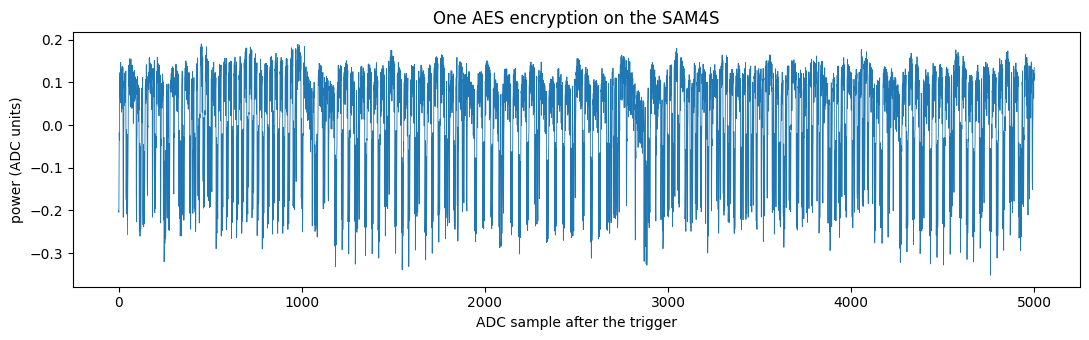

In [8]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

scope.adc.samples = 5000
scope.gain.db = 25
print("samples:", scope.adc.samples, "| gain:", scope.gain.db, "dB | adc_mul:", scope.clock.adc_mul)

def capture_one(text):
    scope.arm()
    target.simpleserial_write('p', text)
    if scope.capture():
        return None, None                      # timed out waiting for the trigger
    ct = target.simpleserial_read('r', 16)
    return np.array(scope.get_last_trace()), ct

key, text = ktp.next()
tr, ct = capture_one(text)
print("trace min / max: %.3f / %.3f   (range is -0.5 .. +0.5)" % (tr.min(), tr.max()))

plt.figure(figsize=(11, 3.5))
plt.plot(tr, lw=0.6)
plt.xlabel("ADC sample after the trigger"); plt.ylabel("power (ADC units)")
plt.title("One AES encryption on the SAM4S")
plt.tight_layout(); plt.show()

## Capture N traces with random plaintexts

Every trace gets a fresh random plaintext under the **same** key. Store the trace and the plaintext; the
plaintext is the known input CPA needs. `sca101` quotes about 50 traces, but that is for its STM32 target.
On our CW312T-SAM4S the leak is weaker. On the course bench, byte 0 came out reliably at around 150 traces
and 15-16 of the 16 bytes at 500. Capturing 500 takes a few seconds, so take them all and find out below
how many were actually needed.

In [9]:
N_TRACES = 500      # knob: how many traces to capture

traces, textins = [], []
key, text = ktp.next()
t0 = time.time()
while len(traces) < N_TRACES:
    tr, ct = capture_one(text)
    if tr is None:
        print("target timed out - resetting"); reboot_flush()
        continue
    traces.append(tr)
    textins.append(list(text))
    key, text = ktp.next()
traces  = np.array(traces)
textins = np.array(textins, dtype=np.uint8)
KEY     = np.array(list(key), dtype=np.uint8)   # the key we loaded - used only to CHECK the result
print(f"captured {traces.shape[0]} traces x {traces.shape[1]} samples in {time.time()-t0:.1f}s")

captured 500 traces x 5000 samples in 4.7s


## Before the statistics: can you see the key by eye?

Overlay a handful of the captured traces. Each one encrypted a **different** plaintext, so the S-box
output differed in every one of them. If that showed up by eye, this would be SPA (page 04) and we would be
done. The zoom on the right is samples 1850-2010; on the course bench the byte-0 leak turned out to sit
there (sample 1932). Check it against your own `t_leak` after the CPA.

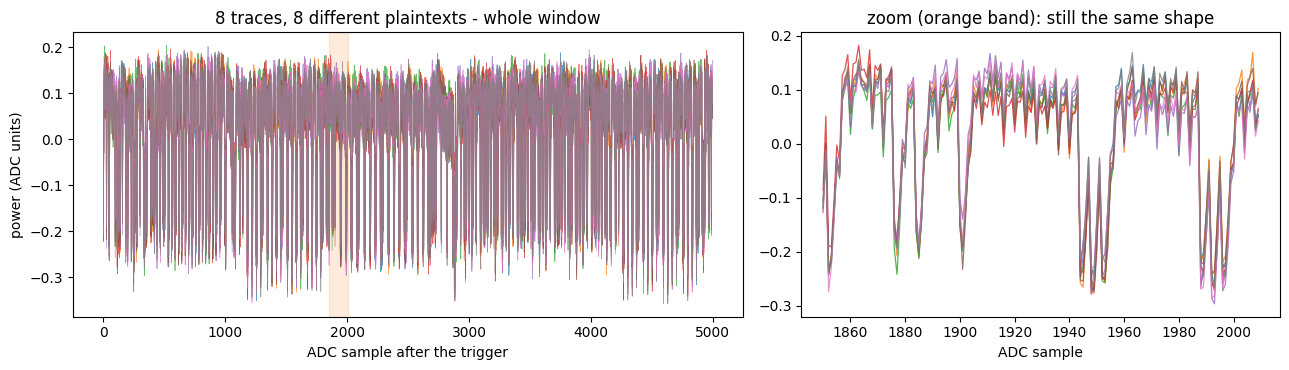

In [10]:
LEAK_GUESS_WINDOW = (1850, 2010)        # zoom window; the course bench leaked at sample 1932
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
for i in range(8):
    ax1.plot(traces[i], lw=0.5, alpha=0.7)
    ax2.plot(range(*LEAK_GUESS_WINDOW), traces[i][slice(*LEAK_GUESS_WINDOW)], lw=0.9, alpha=0.8)
ax1.axvspan(*LEAK_GUESS_WINDOW, color="tab:orange", alpha=0.15)
ax1.set_xlabel("ADC sample after the trigger"); ax1.set_ylabel("power (ADC units)")
ax1.set_title("8 traces, 8 different plaintexts - whole window")
ax2.set_xlabel("ADC sample"); ax2.set_title("zoom (orange band): still the same shape")
plt.tight_layout(); plt.show()

## CPA on one key byte

For each guess `k` of `key[0]` (0..255):

1. **Hypothetical power** - for every trace, `h = HW(Sbox[pt[0] XOR k])`. One number per trace.
2. **Measured power** - at each sample point `j`, the column `traces[:, j]`. One number per trace.
3. **Correlate** the two columns with Pearson's `r`, at every sample point.

A wrong guess predicts weights that have nothing to do with the real leak, so `r` stays near 0 at every
sample. The right guess predicts the real leak, so `|r|` jumps at the instant `v` is computed. Take the
**absolute** value: the shunt measurement can invert the sign. The guess with the largest `|r|` anywhere in
the window is the key byte.

In [11]:
SBOX = np.array([
    0x63,0x7c,0x77,0x7b,0xf2,0x6b,0x6f,0xc5,0x30,0x01,0x67,0x2b,0xfe,0xd7,0xab,0x76,
    0xca,0x82,0xc9,0x7d,0xfa,0x59,0x47,0xf0,0xad,0xd4,0xa2,0xaf,0x9c,0xa4,0x72,0xc0,
    0xb7,0xfd,0x93,0x26,0x36,0x3f,0xf7,0xcc,0x34,0xa5,0xe5,0xf1,0x71,0xd8,0x31,0x15,
    0x04,0xc7,0x23,0xc3,0x18,0x96,0x05,0x9a,0x07,0x12,0x80,0xe2,0xeb,0x27,0xb2,0x75,
    0x09,0x83,0x2c,0x1a,0x1b,0x6e,0x5a,0xa0,0x52,0x3b,0xd6,0xb3,0x29,0xe3,0x2f,0x84,
    0x53,0xd1,0x00,0xed,0x20,0xfc,0xb1,0x5b,0x6a,0xcb,0xbe,0x39,0x4a,0x4c,0x58,0xcf,
    0xd0,0xef,0xaa,0xfb,0x43,0x4d,0x33,0x85,0x45,0xf9,0x02,0x7f,0x50,0x3c,0x9f,0xa8,
    0x51,0xa3,0x40,0x8f,0x92,0x9d,0x38,0xf5,0xbc,0xb6,0xda,0x21,0x10,0xff,0xf3,0xd2,
    0xcd,0x0c,0x13,0xec,0x5f,0x97,0x44,0x17,0xc4,0xa7,0x7e,0x3d,0x64,0x5d,0x19,0x73,
    0x60,0x81,0x4f,0xdc,0x22,0x2a,0x90,0x88,0x46,0xee,0xb8,0x14,0xde,0x5e,0x0b,0xdb,
    0xe0,0x32,0x3a,0x0a,0x49,0x06,0x24,0x5c,0xc2,0xd3,0xac,0x62,0x91,0x95,0xe4,0x79,
    0xe7,0xc8,0x37,0x6d,0x8d,0xd5,0x4e,0xa9,0x6c,0x56,0xf4,0xea,0x65,0x7a,0xae,0x08,
    0xba,0x78,0x25,0x2e,0x1c,0xa6,0xb4,0xc6,0xe8,0xdd,0x74,0x1f,0x4b,0xbd,0x8b,0x8a,
    0x70,0x3e,0xb5,0x66,0x48,0x03,0xf6,0x0e,0x61,0x35,0x57,0xb9,0x86,0xc1,0x1d,0x9e,
    0xe1,0xf8,0x98,0x11,0x69,0xd9,0x8e,0x94,0x9b,0x1e,0x87,0xe9,0xce,0x55,0x28,0xdf,
    0x8c,0xa1,0x89,0x0d,0xbf,0xe6,0x42,0x68,0x41,0x99,0x2d,0x0f,0xb0,0x54,0xbb,0x16,
], dtype=np.uint8)
HW = np.array([bin(x).count("1") for x in range(256)], dtype=np.float64)

def cpa_byte(traces, pts, byte):
    """|r| for every guess (rows) at every sample (columns), for one key byte."""
    t  = traces - traces.mean(axis=0)                        # centre each sample column
    tn = np.sqrt((t ** 2).sum(axis=0))
    guesses = np.arange(256, dtype=np.uint8)
    h  = HW[SBOX[pts[:, byte][None, :] ^ guesses[:, None]]]  # 256 x N hypothetical power
    h  = h - h.mean(axis=1, keepdims=True)
    hn = np.sqrt((h ** 2).sum(axis=1, keepdims=True))
    with np.errstate(invalid="ignore", divide="ignore"):
        r  = (h @ t) / (hn * tn)                             # Pearson r, 256 x samples
    return np.nan_to_num(np.abs(r))                         # a constant column (tiny n) gives 0/0

BYTE = 0
r = cpa_byte(traces, textins, BYTE)
peak = r.max(axis=1)                       # best |r| anywhere in the window, per guess
best = int(np.argmax(peak))
second = np.sort(peak)[-2]
t_leak = int(np.argmax(r[best]))
print(f"recovered key[{BYTE}] = 0x{best:02X}   |r| = {peak[best]:.3f} at sample {t_leak}")
print(f"best wrong guess |r| = {second:.3f}   (margin {peak[best]-second:.3f})")
print(f"known key[{BYTE}]     = 0x{KEY[BYTE]:02X}   ->", "MATCH" if best == KEY[BYTE] else "WRONG")

recovered key[0] = 0x2B   |r| = 0.356 at sample 1932
best wrong guess |r| = 0.238   (margin 0.117)
known key[0]     = 0x2B   -> MATCH


## The correlation plot

Left: the best `|r|` of each of the 256 guesses. The right guess is one bar far above a flat band of 255
wrong ones. On this target expect the right guess near |r| = 0.3-0.5 and the wrong ones a step
below - not the 0.9 of a textbook plot. Right: `|r|` against sample index - every wrong guess in gray, the recovered guess on top. The
spike marks the instant the S-box output for byte 0 was computed.

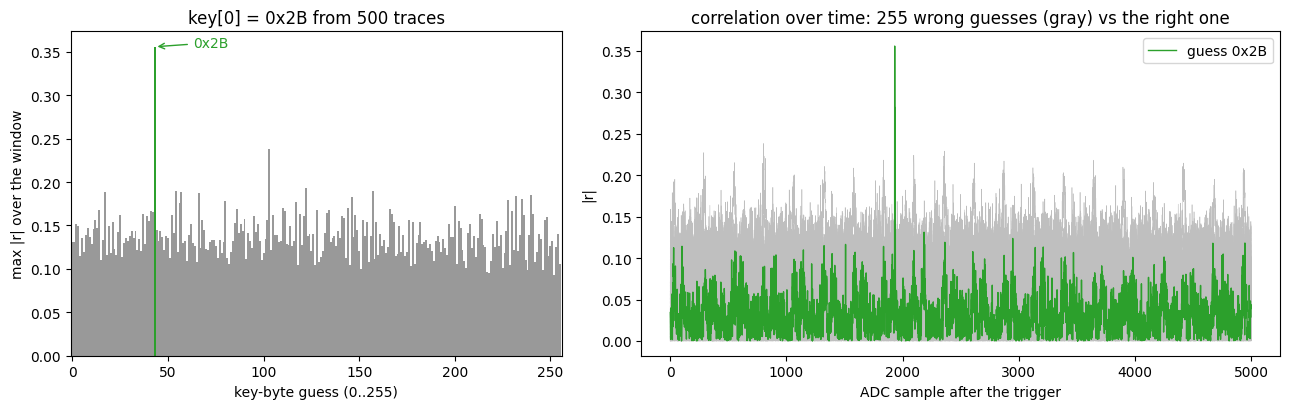

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
cols = ["tab:green" if g == best else "0.6" for g in range(256)]
ax1.bar(range(256), peak, color=cols, width=1.0)
ax1.set_xlim(-1, 256); ax1.set_xlabel("key-byte guess (0..255)"); ax1.set_ylabel("max |r| over the window")
ax1.set_title(f"key[{BYTE}] = 0x{best:02X} from {len(traces)} traces")
ax1.annotate(f"0x{best:02X}", (best, peak[best]), xytext=(best + 20, peak[best]),
             arrowprops=dict(arrowstyle="->", color="tab:green"), color="tab:green")

for g in range(256):
    if g != best:
        ax2.plot(r[g], color="0.75", lw=0.4)
ax2.plot(r[best], color="tab:green", lw=1.0, label=f"guess 0x{best:02X}")
ax2.set_xlabel("ADC sample after the trigger"); ax2.set_ylabel("|r|")
ax2.set_title("correlation over time: 255 wrong guesses (gray) vs the right one")
ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

## Before / after: the leak in the raw traces

The correlation is one number per guess. This plot shows what that number is made of. Split the traces into
groups by the Hamming weight a guess **predicts** for them, and average each group, so you get one mean
trace per predicted weight. Do it for the right guess (top) and for an arbitrary wrong one (bottom). Groups
with fewer than 10 traces are left out: HW 0 and HW 8 each cover 1 of the 256 byte values, so only a few
traces land there and their means are noise.

- **Left, right guess:** at `t_leak` (red line) the mean traces fan out **in colour order**. Away from
  `t_leak` they lie on top of each other. That instant is when the chip handles `Sbox[pt XOR k]`.
- **Left, wrong guess:** the same traces grouped by a wrong prediction. The mean traces stay on top of each
  other, with no order at `t_leak`.
- **Right column:** the mean power at `t_leak` against the predicted weight. The right guess gives a straight
  slope, which is the leak; the wrong guess gives a flat line. Pearson's `r` measures exactly this slope,
  scaled by the noise. The slope here runs **downwards**: more 1-bits read as lower ADC values, because
  the shunt inverts the sign (week 8, page 02). That is why the attack takes `|r|`.

The fan is a few hundredths of an ADC unit, against a trace that swings over about 0.5. In single traces
it is buried. It shows up only once the traces are sorted by a prediction and averaged, which is why CPA
works where staring at the traces (above) does not.

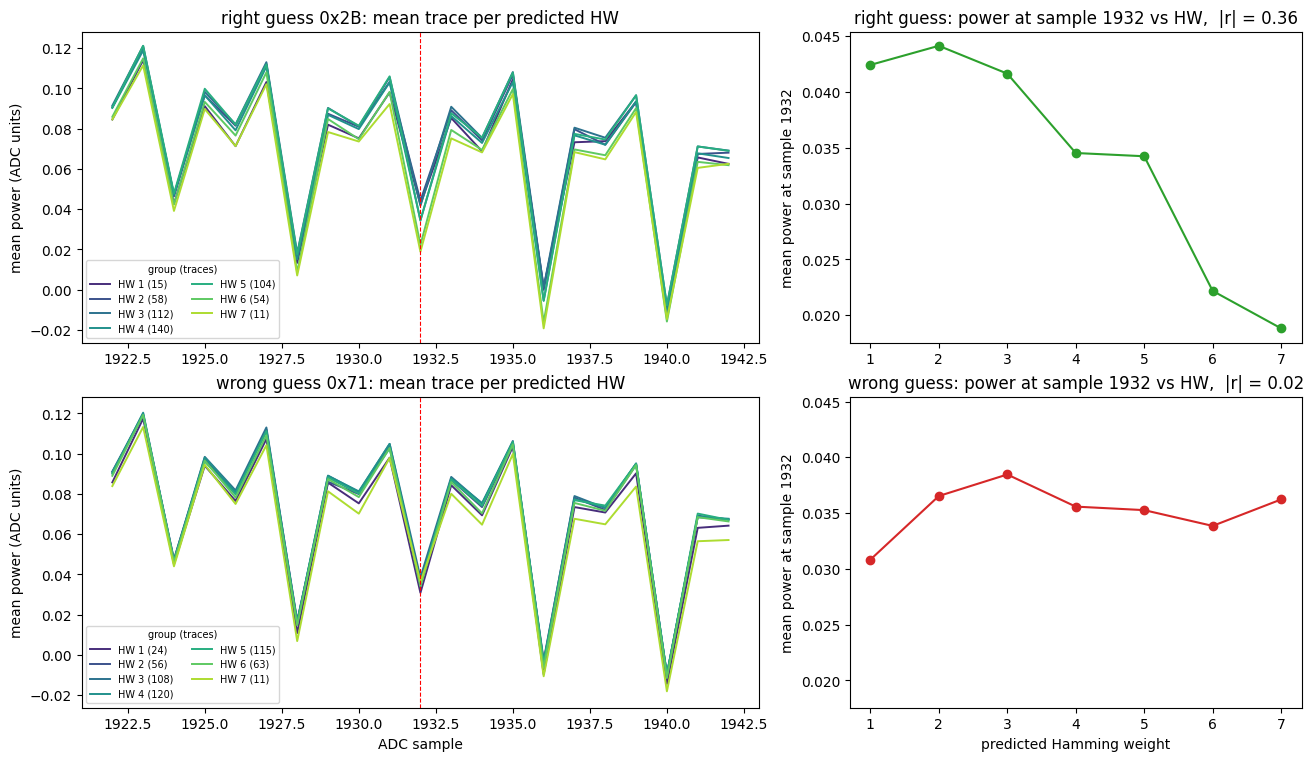

In [13]:
WRONG_GUESS = best ^ 0x5A                # any byte other than the recovered one
lo, hi = t_leak - 10, t_leak + 11
MIN_GROUP = 10
cmap = plt.get_cmap("viridis")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), gridspec_kw={"width_ratios": [1.5, 1]},
                         sharey="col", constrained_layout=True)
for row, (g, name, col) in enumerate([(best, "right", "tab:green"), (WRONG_GUESS, "wrong", "tab:red")]):
    hw = HW[SBOX[textins[:, BYTE] ^ g]]
    ws = [w for w in range(9) if (hw == w).sum() >= MIN_GROUP]
    ax = axes[row, 0]
    for w in ws:
        ax.plot(range(lo, hi), traces[hw == w, lo:hi].mean(axis=0), color=cmap(w / 8), lw=1.4,
                label=f"HW {w} ({int((hw == w).sum())})")
    ax.axvline(t_leak, color="red", ls="--", lw=0.8)
    ax.set_title(f"{name} guess 0x{g:02X}: mean trace per predicted HW")
    ax.set_ylabel("mean power (ADC units)")
    ax.legend(fontsize=7, ncol=2, loc="lower left", title="group (traces)", title_fontsize=7)
    m = [traces[hw == w, t_leak].mean() for w in ws]
    ax2 = axes[row, 1]
    ax2.plot(ws, m, "o-", color=col)
    r_here = abs(np.corrcoef(hw, traces[:, t_leak])[0, 1])
    ax2.set_title(f"{name} guess: power at sample {t_leak} vs HW,  |r| = {r_here:.2f}")
    ax2.set_ylabel(f"mean power at sample {t_leak}")
axes[1, 0].set_xlabel("ADC sample")
axes[1, 1].set_xlabel("predicted Hamming weight")
plt.show()

## How many traces did it take?

Rerun the same attack on the first `n` traces only, for growing `n`, and track the **rank** of the known key
byte (0 = it is the top guess). The count you report is the smallest `n` from which the rank stays 0 for
every larger `n` - a single lucky rank 0 that later drops back does not count.

On the right, both curves start near `|r| = 1`. With only a handful of traces, two short columns of numbers correlate strongly by pure chance, for every guess. As traces add up, the chance correlation of the wrong guesses (red) shrinks towards 0, while the right guess (green) settles at the real strength of the leak. The trace count you report is where red drops below green and stays there.

traces needed (rank stays 0 from here on): 150


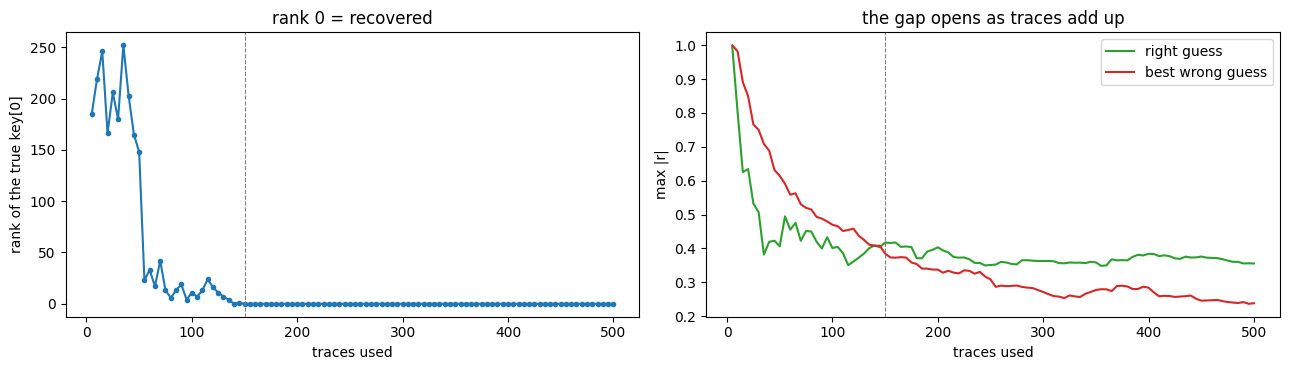

In [14]:
ns = list(range(5, len(traces) + 1, 5))
ranks, r_right, r_wrong = [], [], []
for n in ns:
    p = cpa_byte(traces[:n], textins[:n], BYTE).max(axis=1)
    order = np.argsort(p)[::-1]
    ranks.append(int(np.where(order == KEY[BYTE])[0][0]))
    r_right.append(p[KEY[BYTE]])
    r_wrong.append(np.max(np.delete(p, KEY[BYTE])))

ranks = np.array(ranks)
stable = next((ns[i] for i in range(len(ns)) if (ranks[i:] == 0).all()), None)
print("traces needed (rank stays 0 from here on):", stable)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.plot(ns, ranks, marker=".", color="tab:blue")
ax1.set_xlabel("traces used"); ax1.set_ylabel(f"rank of the true key[{BYTE}]"); ax1.set_title("rank 0 = recovered")
ax2.plot(ns, r_right, color="tab:green", label="right guess")
ax2.plot(ns, r_wrong, color="tab:red",   label="best wrong guess")
if stable:
    for a in (ax1, ax2): a.axvline(stable, color="0.5", ls="--", lw=0.8)
ax2.set_xlabel("traces used"); ax2.set_ylabel("max |r|"); ax2.legend(); ax2.set_title("the gap opens as traces add up")
plt.tight_layout(); plt.show()

## The other 15 bytes

Nothing about byte 0 is special: the same function with `byte = 1..15` attacks each S-box independently
(divide and conquer). All 16 together are the first-round key, which for AES-128 **is** the key.
If a byte or two still come out wrong, those bytes just need more traces: raise `N_TRACES` and capture again.

In [15]:
rec = []
for b in range(16):
    p = cpa_byte(traces, textins, b).max(axis=1)
    rec.append(int(np.argmax(p)))
rec = np.array(rec, dtype=np.uint8)
print("recovered:", bytes(rec).hex())
print("loaded   :", bytes(KEY).hex())
print("bytes correct: %d / 16" % int((rec == KEY).sum()))

recovered: 2b7e151628aed2a6abf7158809cf4f3c
loaded   : 2b7e151628aed2a6abf7158809cf4f3c
bytes correct: 16 / 16


## Submission

A report with a screenshot of the **correlation plot** above (the recovered byte's bar standing clear of the
other 255), plus two numbers:

- the **recovered byte value** (`key[0]`, in hex),
- the **number of traces** it took - the stable count from the rank plot, not just how many you captured.

If the live capture will not cooperate, the analysis is identical on any saved trace set: save `traces` and
`textins` with `np.save` and rerun the CPA cells without the hardware.

> The target never ran wrong. Every trace was a correct encryption.

In [16]:
scope.dis()
target.dis()